In [ ]:
import numpy as np
import matplotlib.pyplot as plt


In [ ]:
%matplotlib qt

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

def gt_point(image, n_points=4):

    if isinstance(image, str):
        image = np.array(Image.open(image).convert("RGB"))

    fig, ax = plt.subplots(figsize=(10, 10))
    ax.imshow(image)
    ax.set_title(f"Select {n_points} Eye Landmarks")
    ax.axis("on")

    plt.show(block=False)

    points = plt.ginput(
        n=n_points,
        timeout=0,
        show_clicks=True
    )

    plt.close(fig)

    points = np.array(points).reshape(-1, 2)

    return points

In [ ]:
image = "images/000000204800.jpg"
image_rgb = plt.imread(image)
gt_points = gt_point(image_rgb, n_points=4)

In [ ]:
gt_points

In [ ]:
dog_eye = array([[280.90584416, 142.49675325],
       [321.44480519, 138.58766234],
       [190.87987013, 515.43181818],
       [234.06168831, 475.21753247]])

In [ ]:
def show_point(image, points):
    fig, ax = plt.subplots(figsize=(10, 10))
    ax.imshow(image)

    for i, (x, y) in enumerate(points):
        ax.scatter(
            x, y,
            color="lime",
            edgecolors="black",
            s=55,
            zorder=5
        )

        ax.text(x + 5, y - 5, f"GT {i+1}", color="yellow")

    ax.axis("on")
    plt.show()



In [ ]:
%matplotlib inline

In [ ]:
show_point(image_rgb, gt_points)

In [ ]:
def distance_between_points(p1, p2):
    return float(np.linalg.norm(np.array(p1) - np.array(p2)))

In [ ]:
dog1_dist = distance_between_points(gt_points[0], gt_points[1])
dog2_dist = distance_between_points(gt_points[2], gt_points[3])
between_dist = distance_between_points(gt_points[0], gt_points[2])

print(f"Dog 1 Inter-eye Distance: {dog1_dist:.2f} px")
print(f"Dog 2 Inter-eye Distance: {dog2_dist:.2f} px")
print(f"Between Dogs Right-eye Distance: {between_dist:.2f} px")

In [ ]:
%matplotlib qt
image = "images/000000114269.jpg"
image_rgb = plt.imread(image)
gt_points = gt_point(image_rgb, n_points=4)

In [ ]:
gt_points

In [ ]:
Ground_truth ={
       # two white dogs
       '000000204800':
              [[280.90584416, 142.49675325],
              [321.44480519, 138.58766234],
              [190.87987013, 515.43181818],
              [234.06168831, 475.21753247]],
       # one dog one cat
       '000000114269':
              [[263.72580645,  74.20322581],
              [330.47419355,  75.1       ],
              [430.93548387, 307.13225806],
              [465.05483871, 304.9516129 ]],
}

In [ ]:
%matplotlib qt

## Mask Label


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import cv2
from matplotlib.widgets import Button

def annotate_polygon(image, label="Animal GT"):
    # Create interactive figure
    fig, ax = plt.subplots(figsize=(12, 9))
    plt.subplots_adjust(bottom=0.15)

    ax.imshow(image)
    ax.set_title(f"{label} | Left click: Add point | Finish button: Save")

    points = []

    # Live polygon outline
    line, = ax.plot(
        [], [], "go-",
        linewidth=1.5,
        markersize=4
    )

    # Add Finish button
    button_ax = fig.add_axes([0.75, 0.03, 0.18, 0.06])
    button = Button(button_ax, "Finish")

    def on_click(event):
        if event.inaxes != ax:
            return

        if event.button != 1:
            return

        # Record clicked coordinates
        points.append([event.xdata, event.ydata])

        # Update visible polygon
        arr = np.array(points)
        line.set_data(arr[:, 0], arr[:, 1])

        ax.set_title(f"{label} | Selected points: {len(points)}")
        fig.canvas.draw_idle()

    def on_finish(event):
        plt.close(fig)

    # Register callbacks
    cid = fig.canvas.mpl_connect("button_press_event", on_click)
    button.on_clicked(on_finish)

    # Keep function running until figure closes
    plt.show(block=True)

    # Validate annotation
    if len(points) < 3:
        print(f"{label}: Only {len(points)} points collected")
        return None, None

    # Convert polygon into mask
    points = np.asarray(points, dtype=np.float32)
    h, w = image.shape[:2]

    mask = np.zeros((h, w), dtype=np.uint8)

    cv2.fillPoly(
        mask,
        [np.round(points).astype(np.int32)],
        color=1
    )

    print(f"{label}: {len(points)} points, {mask.sum()} mask pixels")

    return mask, points

In [ ]:
dog_image = outputs["animal_crops"][dog_idx]["original_crop"]

dog_mask_gt, dog_polygon = annotate_polygon(
    dog_image,
    label="Dog Ground Truth"
)

In [ ]:
%matplotlib inline

In [ ]:
if dog_mask_gt is not None:
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    axes[0].imshow(dog_image)
    axes[0].plot(
        *np.vstack([dog_polygon, dog_polygon[0]]).T,
        "go-", markersize=3
    )
    axes[0].set_title("Annotated Dog Polygon")

    axes[1].imshow(dog_mask_gt, cmap="gray", vmin=0, vmax=1)
    axes[1].set_title("Dog Ground Truth Binary Mask")

    for ax in axes:
        ax.axis("off")

    plt.show()

In [ ]:
gt_animal_masks = {}
gt_animal_polygons = {}

gt_animal_masks["dog"] = dog_mask_gt
gt_animal_polygons["dog"] = dog_polygon

print("Saved dog mask:", gt_animal_masks["dog"].shape, gt_animal_masks["dog"].sum())

In [ ]:
%matplotlib qt

In [ ]:
cat_image = outputs["animal_crops"][cat_idx]["original_crop"]

cat_mask_gt, cat_polygon = annotate_polygon(
    cat_image,
    label="Cat Ground Truth"
)

In [ ]:
gt_animal_masks["cat"] = cat_mask_gt
gt_animal_polygons["cat"] = cat_polygon

print("Saved cat mask:", gt_animal_masks["cat"].shape, gt_animal_masks["cat"].sum())

In [ ]:
import os
import numpy as np

os.makedirs("annotations", exist_ok=True)

image_id = "000000114269"

np.savez_compressed(
    f"annotations/{image_id}_animal_gt.npz",
    **gt_animal_masks
)

print("Animal GT saved:", list(gt_animal_masks.keys()))

In [ ]:
%matplotlib inline

NameError: name 'dog_idx' is not defined

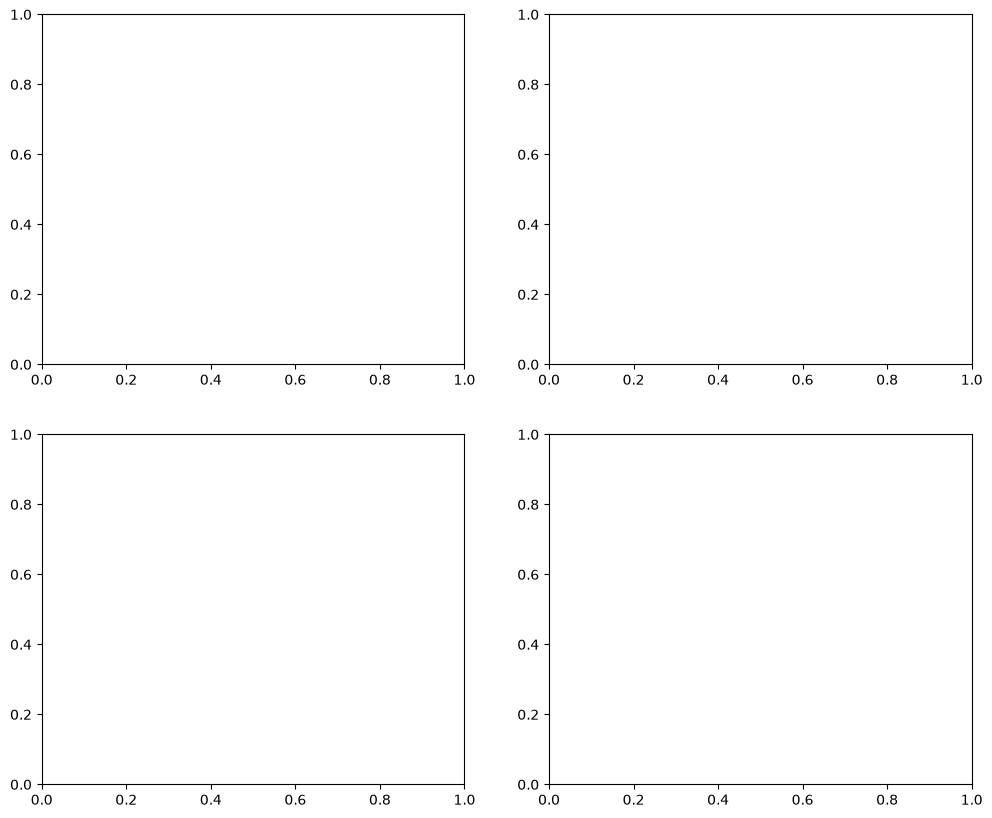

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for row, (animal_idx, animal_name) in enumerate([
    (dog_idx, "dog"),
    (cat_idx, "cat")
]):
    img = outputs["animal_crops"][animal_idx]["original_crop"]
    mask = gt_animal_masks[animal_name]

    # original
    axes[row, 0].imshow(img)
    axes[row, 0].set_title(f"{animal_name.title()} Original")
    axes[row, 0].axis("off")

    # mask overlay
    axes[row, 1].imshow(img)
    axes[row, 1].imshow(
        np.ma.masked_where(mask == 0, mask),
        cmap="spring",
        alpha=0.5
    )
    axes[row, 1].set_title(f"{animal_name.title()} GT Mask")
    axes[row, 1].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
%matplotlib qt

In [ ]:
gt_eye_masks = {}
gt_eye_polygons = {}

In [ ]:
dog_image = outputs["animal_crops"][dog_idx]["original_crop"]

dog_right_eye_mask, dog_right_eye_polygon = annotate_polygon(
    dog_image,
    label="Dog Right Eye"
)

dog_left_eye_mask, dog_left_eye_polygon = annotate_polygon(
    dog_image,
    label="Dog Left Eye"
)

gt_eye_masks["dog_right_eye"] = dog_right_eye_mask
gt_eye_masks["dog_left_eye"] = dog_left_eye_mask

gt_eye_polygons["dog_right_eye"] = dog_right_eye_polygon
gt_eye_polygons["dog_left_eye"] = dog_left_eye_polygon

NameError: name 'annotate_polygon' is not defined

In [ ]:
cat_image = outputs["animal_crops"][cat_idx]["original_crop"]

cat_right_eye_mask, cat_right_eye_polygon = annotate_polygon(
    cat_image,
    label="Cat Right Eye"
)

cat_left_eye_mask, cat_left_eye_polygon = annotate_polygon(
    cat_image,
    label="Cat Left Eye"
)

gt_eye_masks["cat_right_eye"] = cat_right_eye_mask
gt_eye_masks["cat_left_eye"] = cat_left_eye_mask

gt_eye_polygons["cat_right_eye"] = cat_right_eye_polygon
gt_eye_polygons["cat_left_eye"] = cat_left_eye_polygon

In [ ]:
np.savez_compressed(
    f"annotations/{image_id}_eye_gt.npz",
    **gt_eye_masks
)

print("Eye GT saved:", list(gt_eye_masks.keys()))

In [ ]:
%matplotlib inline

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for row, (animal_idx, animal_name) in enumerate([
    (dog_idx, "dog"),
    (cat_idx, "cat")
]):
    img = outputs["animal_crops"][animal_idx]["original_crop"]

    for col, eye_name in enumerate(["right_eye", "left_eye"]):
        key = f"{animal_name}_{eye_name}"
        mask = gt_eye_masks[key]

        axes[row, col].imshow(img)
        axes[row, col].imshow(
            np.ma.masked_where(mask == 0, mask),
            cmap="spring",
            alpha=0.55
        )
        axes[row, col].set_title(f"{animal_name.title()} {eye_name}")
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()